# Without PCA

I am going to train KNN model on the MNIST dataset without applying PCA for now (means on all 784 columns)


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [4]:
df_train = pd.read_csv("/home/ammar/AI Track/ai-foundation-portfolio/Machine-Learning/PCA/Datasets/mnist_train.csv")

In [5]:
df_train.head()

,label,1x1,1x2,1x3,1x4,1x5,1x6,1x7,1x8,1x9,...,28x19,28x20,28x21,28x22,28x23,28x24,28x25,28x26,28x27,28x28
0,5,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,4,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3,1,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,9,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


In [6]:
df_test = pd.read_csv("/home/ammar/AI Track/ai-foundation-portfolio/Machine-Learning/PCA/Datasets/mnist_test.csv")

In [7]:
df_test.head()

,label,1x1,1x2,1x3,1x4,1x5,1x6,1x7,1x8,1x9,...,28x19,28x20,28x21,28x22,28x23,28x24,28x25,28x26,28x27,28x28
0,7,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,2,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,1,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,4,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


In [8]:
df_train.shape

(60000, 785)

In [9]:
df_test.shape

(10000, 785)

In [10]:
from sklearn.neighbors import KNeighborsClassifier

In [11]:
knn = KNeighborsClassifier()

In [19]:
knn.fit(df_train.iloc[:,1:], df_train.iloc[:,0])


,"n_neighbors n_neighbors: int, default=5Number of neighbors to use by default for :meth:`kneighbors` queries.",5
,"weights weights: {'uniform', 'distance'}, callable or None, default='uniform'Weight function used in prediction. Possible values:- 'uniform' : uniform weights. All points in each neighborhood are weighted equally.- 'distance' : weight points by the inverse of their distance. in this case, closer neighbors of a query point will have a greater influence than neighbors which are further away.- [callable] : a user-defined function which accepts an array of distances, and returns an array of the same shape containing the weights.Refer to the example entitled:ref:`sphx_glr_auto_examples_neighbors_plot_classification.py`showing the impact of the `weights` parameter on the decisionboundary.",'uniform'
,"algorithm algorithm: {'auto', 'ball_tree', 'kd_tree', 'brute'}, default='auto'Algorithm used to compute the nearest neighbors:- 'ball_tree' will use :class:`BallTree`- 'kd_tree' will use :class:`KDTree`- 'brute' will use a brute-force search.- 'auto' will attempt to decide the most appropriate algorithm based on the values passed to :meth:`fit` method.Note: fitting on sparse input will override the setting ofthis parameter, using brute force.",'auto'
,"leaf_size leaf_size: int, default=30Leaf size passed to BallTree or KDTree. This can affect thespeed of the construction and query, as well as the memoryrequired to store the tree. The optimal value depends on thenature of the problem.",30
,"p p: float, default=2Power parameter for the Minkowski metric. When p = 1, this is equivalentto using manhattan_distance (l1), and euclidean_distance (l2) for p = 2.For arbitrary p, minkowski_distance (l_p) is used. This parameter is expectedto be positive.",2
,"metric metric: str or callable, default='minkowski'Metric to use for distance computation. Default is ""minkowski"", whichresults in the standard Euclidean distance when p = 2. See thedocumentation of `scipy.spatial.distance<https://docs.scipy.org/doc/scipy/reference/spatial.distance.html>`_ andthe metrics listed in:class:`~sklearn.metrics.pairwise.distance_metrics` for valid metricvalues.If metric is ""precomputed"", X is assumed to be a distance matrix andmust be square during fit. X may be a :term:`sparse graph`, in whichcase only ""nonzero"" elements may be considered neighbors.If metric is a callable function, it takes two arrays representing 1Dvectors as inputs and must return one value indicating the distancebetween those vectors. This works for Scipy's metrics, but is lessefficient than passing the metric name as a string.",'minkowski'
,"metric_params metric_params: dict, default=NoneAdditional keyword arguments for the metric function.",None
,"n_jobs n_jobs: int, default=NoneThe number of parallel jobs to run for neighbors search.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.Doesn't affect :meth:`fit` method.",None
Name,Type,Value
"classes_ classes_: array of shape (n_classes,)Class labels known to the classifier","ndarray[int64](10,)","[0,1,2,...,7,8,9]"
"effective_metric_ effective_metric_: str or callbleThe distance metric used. It will be same as the `metric` parameteror a synonym of it, e.g. 'euclidean' if the `metric` parameter set to'minkowski' and `p` parameter set to 2.",str,'eu...an'


In [20]:
import time 
start = time.time()
y_pred = knn.predict(df_test.iloc[:,1:])
print(time.time()-start)

10.920234441757202


In [21]:
from sklearn.metrics import accuracy_score

In [25]:
accuracy_score(df_test['label'], y_pred)*100

96.88

# With PCA

Now i am going to reduce the number of components and then I will train the model on the new dataset with reduced number of features

In [82]:
from sklearn.preprocessing import StandardScaler

### Mean Centering
Mean centering is a necessary step before doing PCA


In [83]:
scaler = StandardScaler()

In [84]:
X_train = scaler.fit_transform(df_train.iloc[:,1:])
X_test = scaler.transform(df_test.iloc[:,1:])

In [85]:
from sklearn.decomposition import PCA

In [76]:
pca = PCA(n_components=100)
#by default the components values is same as original no of columns

In [89]:
X_train_trf = pca.fit_transform(X_train)
X_test_trf = pca.transform(X_test)

In [78]:
knn.fit(X_train_trf,df_train['label'])

,"n_neighbors n_neighbors: int, default=5Number of neighbors to use by default for :meth:`kneighbors` queries.",5
,"weights weights: {'uniform', 'distance'}, callable or None, default='uniform'Weight function used in prediction. Possible values:- 'uniform' : uniform weights. All points in each neighborhood are weighted equally.- 'distance' : weight points by the inverse of their distance. in this case, closer neighbors of a query point will have a greater influence than neighbors which are further away.- [callable] : a user-defined function which accepts an array of distances, and returns an array of the same shape containing the weights.Refer to the example entitled:ref:`sphx_glr_auto_examples_neighbors_plot_classification.py`showing the impact of the `weights` parameter on the decisionboundary.",'uniform'
,"algorithm algorithm: {'auto', 'ball_tree', 'kd_tree', 'brute'}, default='auto'Algorithm used to compute the nearest neighbors:- 'ball_tree' will use :class:`BallTree`- 'kd_tree' will use :class:`KDTree`- 'brute' will use a brute-force search.- 'auto' will attempt to decide the most appropriate algorithm based on the values passed to :meth:`fit` method.Note: fitting on sparse input will override the setting ofthis parameter, using brute force.",'auto'
,"leaf_size leaf_size: int, default=30Leaf size passed to BallTree or KDTree. This can affect thespeed of the construction and query, as well as the memoryrequired to store the tree. The optimal value depends on thenature of the problem.",30
,"p p: float, default=2Power parameter for the Minkowski metric. When p = 1, this is equivalentto using manhattan_distance (l1), and euclidean_distance (l2) for p = 2.For arbitrary p, minkowski_distance (l_p) is used. This parameter is expectedto be positive.",2
,"metric metric: str or callable, default='minkowski'Metric to use for distance computation. Default is ""minkowski"", whichresults in the standard Euclidean distance when p = 2. See thedocumentation of `scipy.spatial.distance<https://docs.scipy.org/doc/scipy/reference/spatial.distance.html>`_ andthe metrics listed in:class:`~sklearn.metrics.pairwise.distance_metrics` for valid metricvalues.If metric is ""precomputed"", X is assumed to be a distance matrix andmust be square during fit. X may be a :term:`sparse graph`, in whichcase only ""nonzero"" elements may be considered neighbors.If metric is a callable function, it takes two arrays representing 1Dvectors as inputs and must return one value indicating the distancebetween those vectors. This works for Scipy's metrics, but is lessefficient than passing the metric name as a string.",'minkowski'
,"metric_params metric_params: dict, default=NoneAdditional keyword arguments for the metric function.",None
,"n_jobs n_jobs: int, default=NoneThe number of parallel jobs to run for neighbors search.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.Doesn't affect :meth:`fit` method.",None
Name,Type,Value
"classes_ classes_: array of shape (n_classes,)Class labels known to the classifier","ndarray[int64](10,)","[0,1,2,...,7,8,9]"
"effective_metric_ effective_metric_: str or callbleThe distance metric used. It will be same as the `metric` parameteror a synonym of it, e.g. 'euclidean' if the `metric` parameter set to'minkowski' and `p` parameter set to 2.",str,'eu...an'


### It took less time now because no. of columns are reduced

In [79]:
start_2 = time.time()
knn.predict(X_test_trf)
print(time.time()-start_2)

1.297438383102417


### Accuracy is almost the same
we have decreased the no. of columns from 784 to 100 but accuracy is almost same

In [80]:
accuracy_score(df_test['label'], knn.predict(X_test_trf))

0.9575

## Checking the change in accuracy by change in the no. of principal components

In [91]:
for i in range(1,784):
    pca = PCA(n_components=i)
    X_train_trf = pca.fit_transform(X_train)
    X_test_trf = pca.transform(X_test)
    knn.fit(X_train_trf,df_train['label'])
    print(accuracy_score(df_test['label'], knn.predict(X_test_trf)))
    
    

0.2563
0.3197
0.5194
0.668
0.738
0.8348
0.8453
0.876
0.8893
0.9075
0.9146
0.9202
0.928
0.9362
0.9378
0.9387
0.9409
0.9416
0.9457
0.946
0.9462
0.9471
0.9491
0.949
0.9493
0.9496
0.9505
0.9527
0.9513
0.9523
0.9525
0.9538
0.954
0.9552
0.9568
0.9566
0.9573
0.9579
0.9581
0.9579
0.9586
0.9589
0.9586
0.9576
0.9577
0.9578
0.9575
0.9581
0.9577
0.9578
0.958
0.9582
0.9579
0.9585
0.9581
0.958
0.9583
0.9578
0.9581
0.9583
0.9583
0.9582
0.958
0.9579
0.9577
0.958
0.9582
0.9573
0.9575
0.9576
0.9577
0.9571
0.9569
0.957
0.9566
0.957
0.9571
0.9568
0.9575
0.9577
0.9577
0.9577
0.9579
0.9578
0.9578
0.9579
0.9577
0.9583
0.9581
0.9582
0.9584
0.958
0.9582
0.9582
0.9583
0.9582
0.9582
0.9582
0.958
0.9575
0.9569
0.9571
0.9573
0.957
0.9571
0.9573
0.9573
0.9578
0.9571
0.9569
0.9561
0.9567
0.9566
0.9567
0.9568
0.957
0.9572
0.9572
0.9572
0.9571
0.957
0.9574
0.9575
0.9574
0.957
0.9571
0.9571
0.9567
0.9566
0.9564
0.9563
0.956
0.9559
0.9558
0.9555
0.9559
0.9557
0.9554
0.9559
0.956
0.956
0.9558
0.9556
0.9558
0.9558
0.9553


KeyboardInterrupt: 

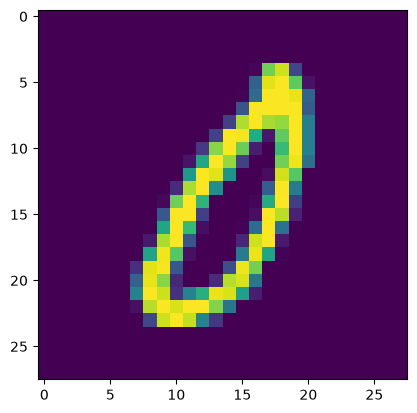

In [93]:
plt.imshow(df.iloc[6819,1:].values.reshape(28,28))

In [102]:
df.sample()

,label,1x1,1x2,1x3,1x4,1x5,1x6,1x7,1x8,1x9,...,28x19,28x20,28x21,28x22,28x23,28x24,28x25,28x26,28x27,28x28
19804,1,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


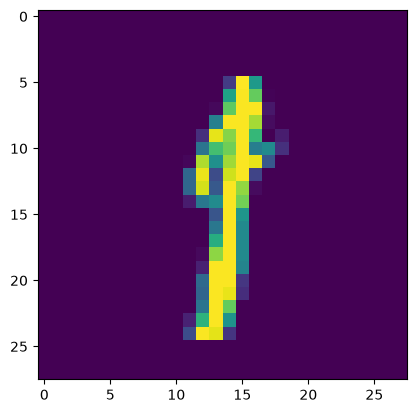

In [103]:
plt.imshow(df.iloc[19804,1:].values.reshape(28,28))

### 2D Visualization

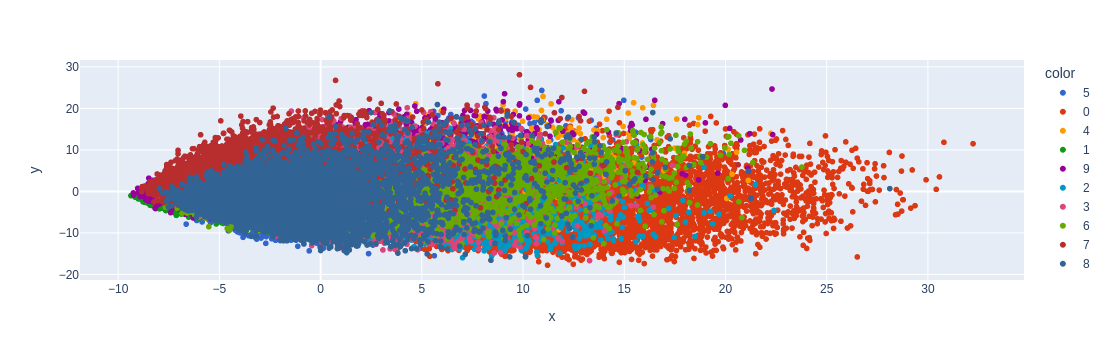

In [105]:
import plotly.express as px
y_train_trf = df_train['label'].astype(str)
fig = px.scatter(x=X_train_trf[:,0],
                 y=X_train_trf[:,1],
                 color=y_train_trf,
                 color_discrete_sequence=px.colors.qualitative.G10
                )
fig.show()

import plotly.express as px
y_train_trf = y_train.astype(str)
fig = px.scatter_3d(df, x=X_train_trf[:,0], y=X_train_trf[:,1], z=X_train_trf[:,2],
              color=y_train_trf)
fig.update_layout(
    margin=dict(l=20, r=20, t=20, b=20),
    paper_bgcolor="LightSteelBlue",
)
fig.show()



### 3D Visualization

In [106]:
pca = PCA(n_components=3)
X_train_trf = pca.fit_transform(X_train)
X_test_trf = pca.transform(X_test)

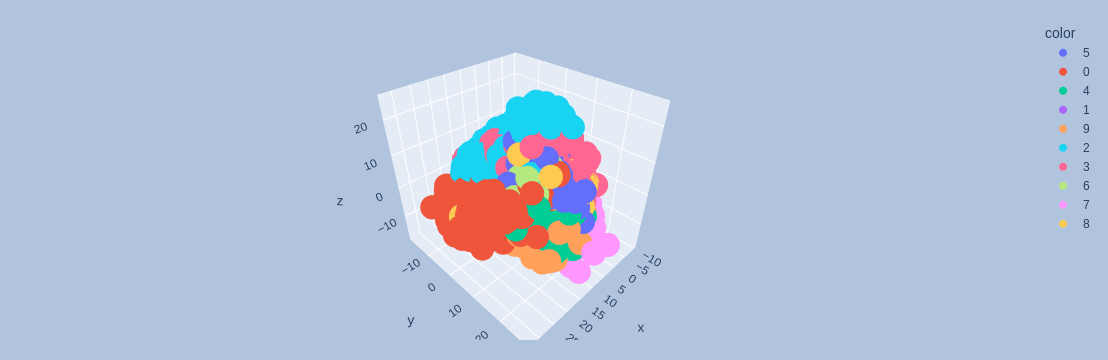

In [108]:
import plotly.express as px
y_train_trf = df_train['label'].astype(str)
fig = px.scatter_3d(df, x=X_train_trf[:,0], y=X_train_trf[:,1], z=X_train_trf[:,2],
              color=y_train_trf)
fig.update_layout(
    margin=dict(l=20, r=20, t=20, b=20),
    paper_bgcolor="LightSteelBlue",
)
fig.show()

### Explained Variance
We can find the optimum no. of Principal Components by checking the explained variance (Eigen Values) of each new eigen vector.
This will tell us the percentage contribution of each variance to the original variance

In [109]:
pca.explained_variance_
# this tells us the eigen values of our 3 principal components

array([40.48763511, 29.24169752, 26.81180449])

In [110]:
pca.components_
# this tells us the new eigen vectors

array([[-0., -0., -0., ..., -0., -0., -0.],
       [ 0.,  0.,  0., ...,  0.,  0.,  0.],
       [-0., -0., -0., ..., -0., -0., -0.]], shape=(3, 784))

In [112]:
pca.explained_variance_ratio_
# this tells the percentage contribution of variance to the original data

array([0.05646717, 0.04078272, 0.0373938 ])

### Checking where the variance contribution is atleast 90%

In [121]:
pca = PCA()

In [122]:
X_train_trf = pca.fit_transform(X_train)
X_test_trf = pca.transform(X_test)

In [123]:
pca.explained_variance_

array([4.04876351e+01, 2.92416975e+01, 2.68118045e+01, 2.06866182e+01,
       1.80766501e+01, 1.57331779e+01, 1.37906091e+01, 1.25175891e+01,
       1.10067953e+01, 1.00504971e+01, 9.62045779e+00, 8.63097356e+00,
       7.99159687e+00, 7.81488215e+00, 7.37553786e+00, 7.13058751e+00,
       6.71398002e+00, 6.60400749e+00, 6.40604846e+00, 6.23737743e+00,
       5.93229172e+00, 5.76059855e+00, 5.48403364e+00, 5.31859721e+00,
       5.12873534e+00, 4.96062446e+00, 4.90533662e+00, 4.70843497e+00,
       4.52919760e+00, 4.39470849e+00, 4.27522172e+00, 4.21399693e+00,
       4.09838079e+00, 4.03181137e+00, 3.97713624e+00, 3.86052409e+00,
       3.80864021e+00, 3.72563426e+00, 3.64393543e+00, 3.44169730e+00,
       3.41624517e+00, 3.36378527e+00, 3.25773631e+00, 3.23620323e+00,
       3.20478100e+00, 3.17911021e+00, 3.14205728e+00, 3.08588859e+00,
       3.06076556e+00, 3.03759974e+00, 2.90171955e+00, 2.86408562e+00,
       2.84980787e+00, 2.82374220e+00, 2.76632955e+00, 2.71778127e+00,
      

In [124]:
pca.explained_variance_ratio_

array([5.64671692e-02, 4.07827199e-02, 3.73938042e-02, 2.88511485e-02,
       2.52110863e-02, 2.19426996e-02, 1.92334439e-02, 1.74579923e-02,
       1.53509230e-02, 1.40171960e-02, 1.34174302e-02, 1.20374194e-02,
       1.11456955e-02, 1.08992356e-02, 1.02864922e-02, 9.94486564e-03,
       9.36383280e-03, 9.21045666e-03, 8.93436778e-03, 8.69912619e-03,
       8.27363019e-03, 8.03417369e-03, 7.64845500e-03, 7.41772464e-03,
       7.15292868e-03, 6.91846831e-03, 6.84135964e-03, 6.56674546e-03,
       6.31676724e-03, 6.12919839e-03, 5.96255295e-03, 5.87716416e-03,
       5.71591699e-03, 5.62307416e-03, 5.54682002e-03, 5.38418374e-03,
       5.31182250e-03, 5.19605602e-03, 5.08211255e-03, 4.80005571e-03,
       4.76455820e-03, 4.69139360e-03, 4.54348956e-03, 4.51345787e-03,
       4.46963401e-03, 4.43383155e-03, 4.38215469e-03, 4.30381751e-03,
       4.26877901e-03, 4.23647017e-03, 4.04696121e-03, 3.99447403e-03,
       3.97456119e-03, 3.93820800e-03, 3.85813590e-03, 3.79042674e-03,
      

In [125]:
cumulative_sum = np.cumsum(pca.explained_variance_ratio_)
cumulative_sum
# this will sum all the variance percentages cumulatively and we will check at how much no. of components the values becomes 90%

array([0.05646717, 0.09724989, 0.13464369, 0.16349484, 0.18870593,
       0.21064863, 0.22988207, 0.24734006, 0.26269099, 0.27670818,
       0.29012561, 0.30216303, 0.31330873, 0.32420796, 0.33449446,
       0.34443932, 0.35380315, 0.36301361, 0.37194798, 0.3806471 ,
       0.38892074, 0.39695491, 0.40460336, 0.41202109, 0.41917402,
       0.42609249, 0.43293384, 0.43950059, 0.44581736, 0.45194656,
       0.45790911, 0.46378627, 0.46950219, 0.47512526, 0.48067208,
       0.48605627, 0.49136809, 0.49656415, 0.50164626, 0.50644631,
       0.51121087, 0.51590227, 0.52044576, 0.52495921, 0.52942885,
       0.53386268, 0.53824483, 0.54254865, 0.54681743, 0.5510539 ,
       0.55510086, 0.55909534, 0.5630699 , 0.56700811, 0.57086624,
       0.57465667, 0.57841069, 0.58211845, 0.5857679 , 0.5893609 ,
       0.59288472, 0.59636266, 0.59980677, 0.60320546, 0.606565  ,
       0.60991386, 0.6132325 , 0.61646276, 0.61962553, 0.62275797,
       0.62586528, 0.62893771, 0.63198685, 0.63501403, 0.63800

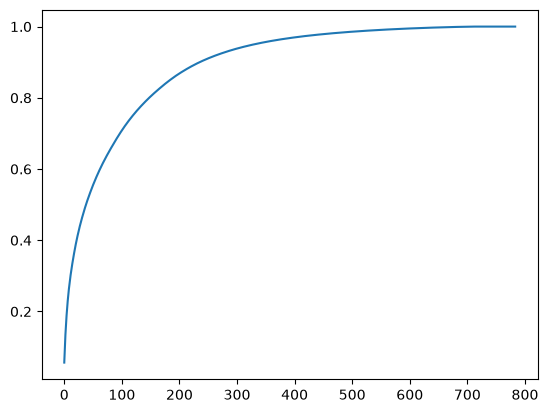

In [126]:
plt.plot(cumulative_sum)
#we should select the principal components bw 300-350 because they are showing 90% variance and we need only that